# Build a window function (mask) with holes

Start from `np.ones((Nmesh, Nmesh))` and punch a few circles and rectangles of zeros
until ~20% of the area is masked, then save as an `.npz` (key `window`).

Feed it to the fit/sampler via `--window-path`:
```bash
bash codex/run_likelihood_z1.sh --data-snapshot data/output_80/snapshot_007.hdf5 \
    --freeze-ic-prior --tie-residual-to-total --fixed-sigma2 7.0 \
    --window-path codex/window_holes.npz --output codex/results/map_z1_wf.pt
```
The HMC sampler inherits the window automatically from the MAP bundle. The likelihood
multiplies **both** the data and the prediction by this window before forming chi^2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Nmesh = 128            # must match the fit's --ngrid
BoxSize = 250.0        # Mpc/h, only for plot axes
target_cover = 0.15    # fraction of area set to zero
seed = 15
out_path = 'window_holes.npz'   # saved relative to this notebook (codex/)

rng = np.random.default_rng(seed)
wf = np.ones((Nmesh, Nmesh))
yy, xx = np.mgrid[0:Nmesh, 0:Nmesh]

def punch_circle(wf, cx, cy, r):
    wf[(xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2] = 0.0

def punch_rect(wf, x0, y0, w, h):
    wf[max(0, y0):y0 + h, max(0, x0):x0 + w] = 0.0

# Alternate circles and rectangles of random size/position until ~20% is masked.
shapes = []
while (wf == 0).mean() < target_cover:
    if rng.random() < 0.5:
        cx, cy, r = rng.integers(0, Nmesh), rng.integers(0, Nmesh), int(rng.integers(15, 25))
        punch_circle(wf, cx, cy, r); shapes.append(('circle', cx, cy, r))
    else:
        x0, y0 = rng.integers(0, Nmesh), rng.integers(0, Nmesh)
        w, h = int(rng.integers(8, 28)), int(rng.integers(15, 25))
        punch_rect(wf, x0, y0, w, h); shapes.append(('rect', x0, y0, w, h))

covered = float((wf == 0).mean())
print(f'masked fraction = {covered:.3f}  ({len(shapes)} shapes: '
      f"{sum(s[0]=='circle' for s in shapes)} circles, {sum(s[0]=='rect' for s in shapes)} rects)")

masked fraction = 0.162  (4 shapes: 1 circles, 3 rects)


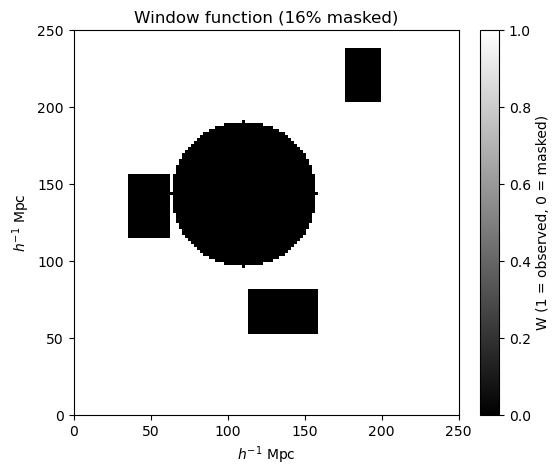

In [2]:
fig, ax = plt.subplots(1, 1, figsize=(5.5, 5))
im = ax.imshow(wf, origin='lower', extent=[0, BoxSize, 0, BoxSize], cmap='gray', vmin=0, vmax=1)
ax.set_title(f'Window function ({covered*100:.0f}% masked)')
ax.set_xlabel(r'$h^{-1}$ Mpc'); ax.set_ylabel(r'$h^{-1}$ Mpc')
fig.colorbar(im, ax=ax, fraction=0.046, label='W (1 = observed, 0 = masked)')
plt.show()

In [3]:
# Save the window plus the shape coordinates (so plots can outline the holes).
#   circles: rows of (cx, cy, r);  rects: rows of (x0, y0, w, h)  -- all in pixel units.
circles = np.array([[s[1], s[2], s[3]] for s in shapes if s[0] == 'circle'], dtype=float).reshape(-1, 3)
rects = np.array([[s[1], s[2], s[3], s[4]] for s in shapes if s[0] == 'rect'], dtype=float).reshape(-1, 4)
np.savez(out_path, window=wf.astype(np.float32), circles=circles, rects=rects)
print('saved', out_path, '| shape', wf.shape, '|', len(circles), 'circles,', len(rects), 'rects')
# sanity: it reloads with the key the loader expects
chk = np.load(out_path)
print('reload ok:', chk['window'].shape, '| masked frac', float((chk['window'] == 0).mean()))

saved window_holes.npz | shape (128, 128) | 1 circles, 3 rects
reload ok: (128, 128) | masked frac 0.16162109375
